# India SaaS CTC Prediction — Research Notebook

Grew out of a **B2B SaaS Metrics** course module (SaaS fundamentals, business models,
pricing models, and growth metrics: ARR, Churn, CAC, LTV, NDR, Rule of 40, Magic
Number, TAM/SAM/SOM) plus a final-year ML internship project.

**What this notebook does:** predicts a P25/P50/P75 **cash CTC** range for roles at
Indian SaaS companies, where a hiring company's *actual computed unit economics* —
not a guessed funding-round label — is a real input feature. It also splits the
prediction into its statutory CTC components and explains every prediction with SHAP.

**On the data:** `data/india_saas_ctc_dataset.csv` is seeded, synthetic, and labeled as
such — real payroll data is confidential and not something this project has legal
access to. What makes it *calibrated* rather than arbitrary: base pay bands, city
premiums, and the cross-border premium are anchored to real 2026 India SaaS
compensation ranges (cited below), and every synthetic company's health score is
computed by the exact same `saas_metrics.py` functions the live `/saas-metrics`
calculator uses — not a separate shortcut.

**Sources for the calibration constants:**
- Chennai engineers ~Rs.7.9-8.7 LPA; Bengaluru structurally higher (concentrates
  product/AI/senior-IC work); Freshworks/Zoho-tier SaaS Rs.6-12 LPA; funded
  startups/unicorns Rs.15-30 LPA; cross-border/FAANG-tier Rs.35-60 LPA.
- India's Code on Wages (enforced 2026-04-01): Basic+DA >=50% of CTC. HRA ~40% of
  Basic (non-metro) / 50% (metro). Employer EPF = 12% of Basic. Gratuity accrual
  ~4.81% of Basic.
- NDR: industry median ~106%, top-quartile >=120% (KeyBanc Capital Markets).


In [1]:
import sys
sys.path.insert(0, r"C:\Users\Zenith Joshua\Downloads\SalaryPredictor-main\SalaryPredictor-main")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

import saas_metrics as sm
import saas_domain as domain
from ctc_rules import compute_ctc_breakup
from train_model import build_preprocessor, CATEGORICAL_FEATURES, NUMERIC_FEATURES, FEATURE_COLUMNS, TARGET

pd.set_option("display.max_columns", 20)
np.random.seed(42)


C:\Users\Zenith Joshua\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. SaaS unit-economics formulas

Every formula below is implemented in `saas_metrics.py`, with its threshold cited in
the docstring. Worked example first, to sanity-check the implementation against
hand-calculable numbers before trusting it inside the data generator.


In [2]:
arr = sm.compute_arr(mrr=100_000)
gm = sm.compute_gross_margin(revenue=1000, cogs=300)
churn = sm.compute_churn_rate(customers_lost=10, customers_at_period_start=200)
cac = sm.compute_cac(sales_and_marketing_spend=500_000, new_customers_acquired=100)
ltv = sm.compute_ltv(average_revenue_per_account=1200, gross_margin=gm, churn_rate=churn)
ltv_cac = sm.ltv_to_cac_ratio(ltv, cac)
ndr = sm.compute_ndr(118, 100)
rule40 = sm.rule_of_40(yoy_growth_rate_pct=35, profit_margin_pct=10)
magic = sm.saas_magic_number(current_quarter_revenue=120, prior_quarter_revenue=100, prior_quarter_sm_spend=80)
health = sm.saas_health_score(rule40_value=rule40, ndr_value=ndr, ltv_cac_ratio=ltv_cac, arr_per_employee_usd=250_000)

print(f"ARR                 = {arr:,.0f}")
print(f"Gross margin        = {gm:.1%}")
print(f"Churn rate          = {churn:.1%}")
print(f"CAC                 = {cac:,.0f}")
print(f"LTV                 = {ltv:,.0f}")
print(f"LTV:CAC             = {ltv_cac:.2f} : 1  (>=3:1 is the healthy bar)")
print(f"NDR                 = {ndr:.1f}%")
print(f"Rule of 40          = {rule40:.1f}  (>=40 is healthy)")
print(f"SaaS Magic Number   = {magic:.2f}  (>0.75 is efficient)")
print(f"Health score        = {health.score}/100 ({health.band})")
print(f"Cross-border mult.  = {sm.cross_border_premium_multiplier('Cross-border')}x  (Domestic = {sm.cross_border_premium_multiplier('Domestic')}x baseline)")


ARR                 = 1,200,000
Gross margin        = 70.0%
Churn rate          = 5.0%
CAC                 = 5,000
LTV                 = 16,800
LTV:CAC             = 3.36 : 1  (>=3:1 is the healthy bar)
NDR                 = 118.0%
Rule of 40          = 45.0  (>=40 is healthy)
SaaS Magic Number   = 1.00  (>0.75 is efficient)
Health score        = 67.1/100 (Healthy)
Cross-border mult.  = 1.35x  (Domestic = 1.0x baseline)


## 2. Generate the synthetic, benchmark-calibrated dataset

`data/generate_dataset.py` simulates ~1,000 companies (funding stage, target market,
pricing model, and underlying SaaS metrics drawn from stage-appropriate ranges) and
then samples 10-40 employees per company, applying named, documented multipliers
(level/city/funding-stage/target-market/skill/pedigree/pricing-model) plus noise.


In [3]:
df = pd.read_csv(r"C:\Users\Zenith Joshua\Downloads\SalaryPredictor-main\SalaryPredictor-main\data\india_saas_ctc_dataset.csv")
print(f"{len(df):,} rows, {df['company_id'].nunique():,} companies")
df.head()


24,533 rows, 1,000 companies


,company_id,funding_stage,health_score,health_band,target_market,pricing_model,role_archetype,role,years_experience,level,city,saas_hub_tier,skill_category,education_pedigree,cash_ctc_lpa,esop_annualized_lpa
0,0,Series B,56.7,Cash-constrained,Cross-border,Subscription,GTM,Customer Success Manager,0.1,Junior,Indore,Emerging Hub,Data engineering,Regional university,9.37,1.66
1,0,Series B,56.7,Cash-constrained,Cross-border,Subscription,GTM,Sales Development Rep (SDR),3.8,Mid,Kochi,Emerging Hub,Cybersecurity,Regional university,18.16,2.50
2,0,Series B,56.7,Cash-constrained,Cross-border,Subscription,Product,QA Engineer,3.3,Mid,Gurugram,Tier 1 SaaS Hub,Data engineering,Recognised university,24.02,4.32
3,0,Series B,56.7,Cash-constrained,Cross-border,Subscription,Product,Data Scientist,7.1,Senior,Remote (other),Emerging Hub,GenAI / ML,Recognised university,54.14,11.46
4,0,Series B,56.7,Cash-constrained,Cross-border,Subscription,GTM,Account Executive,10.8,Lead / Principal,Bengaluru,Tier 1 SaaS Hub,Cybersecurity,Recognised university,67.98,10.42


In [4]:
df[["years_experience", "health_score", "cash_ctc_lpa", "esop_annualized_lpa"]].describe()


,years_experience,health_score,cash_ctc_lpa,esop_annualized_lpa
count,24533.000000,24533.000000,24533.000000,24533.000000
mean,3.980610,54.746598,24.013274,3.910703
std,3.923426,13.284079,16.072565,3.915034
min,0.000000,18.900000,3.680000,0.000000
25%,1.100000,42.900000,12.830000,0.950000
50%,2.700000,55.900000,19.360000,3.080000
75%,5.500000,65.700000,30.150000,5.530000
max,22.000000,84.200000,159.010000,37.290000


## 3. EDA — do the calibrated premiums actually show up?

If the generator is calibrated correctly, cross-border pay should exceed domestic,
Bengaluru should lead the hub tiers, later funding stages should pay more, and pay
should jump at each level boundary (the step-function this whole modeling comparison
hinges on).


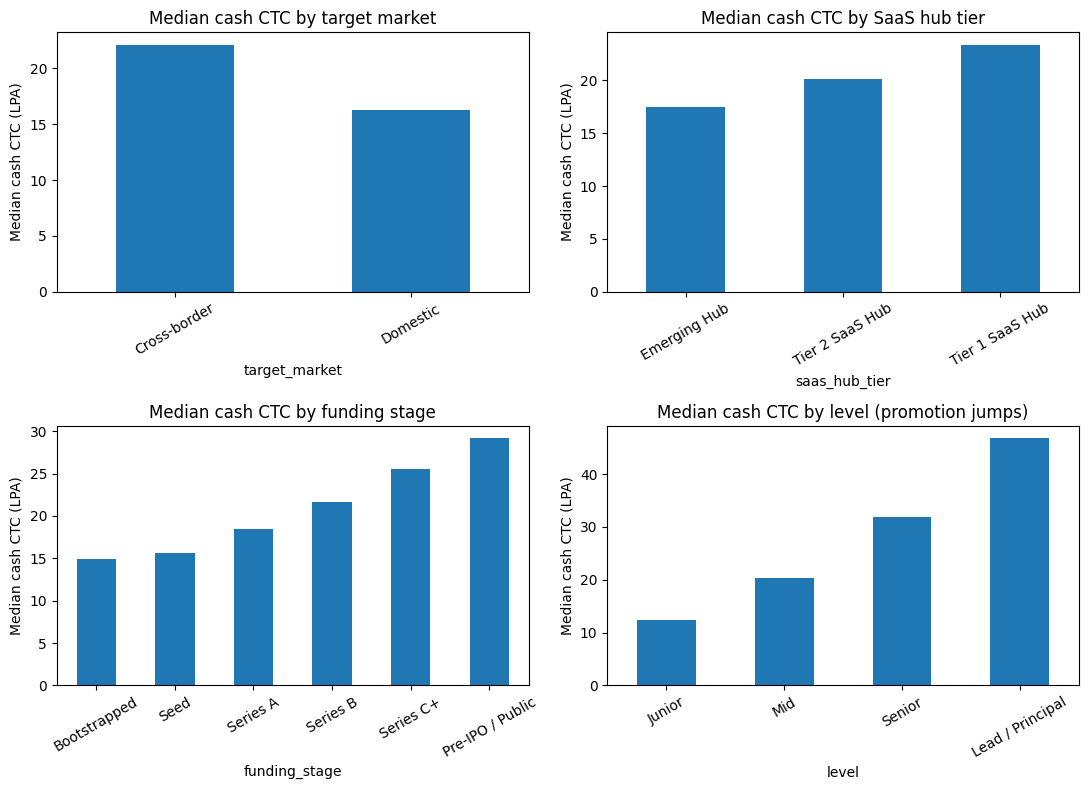

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

df.groupby("target_market")["cash_ctc_lpa"].median().plot(kind="bar", ax=axes[0,0], title="Median cash CTC by target market")
df.groupby("saas_hub_tier")["cash_ctc_lpa"].median().sort_values().plot(kind="bar", ax=axes[0,1], title="Median cash CTC by SaaS hub tier")

stage_order = list(domain.FUNDING_STAGES.keys())
df.groupby("funding_stage")["cash_ctc_lpa"].median().reindex(stage_order).plot(kind="bar", ax=axes[1,0], title="Median cash CTC by funding stage")

level_order = ["Junior", "Mid", "Senior", "Lead / Principal"]
df.groupby("level")["cash_ctc_lpa"].median().reindex(level_order).plot(kind="bar", ax=axes[1,1], title="Median cash CTC by level (promotion jumps)")

for ax in axes.flat:
    ax.set_ylabel("Median cash CTC (LPA)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


In [6]:
print("Health band -> median cash CTC:")
print(df.groupby("health_band")["cash_ctc_lpa"].median().sort_values())


Health band -> median cash CTC:
health_band
At-risk                    14.88
Cash-constrained           17.53
Healthy                    23.22
Hypergrowth / Efficient    26.15
Name: cash_ctc_lpa, dtype: float64


All four premiums are monotonic in the expected direction, and health band tracks pay
even *within* a fixed role/level/city — evidence the health-score feature is carrying
real signal, not decoration.

## 4. Feature engineering & train/test split

Categoricals are one-hot encoded, numerics (`years_experience`, `health_score`) are
standardized, via the shared `build_preprocessor()` in `train_model.py` — the exact
function `main.py` uses at serving time, so train and serve can't silently drift apart.


In [7]:
X = df[FEATURE_COLUMNS]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = build_preprocessor()
X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)
print(f"Train: {X_train_t.shape}, Test: {X_test_t.shape}")


Train: (19626, 53), Test: (4907, 53)


## 5. Baseline: Linear Regression

A sensible first model — but the pay curve has real step-function jumps at each
promotion boundary, which a linear model structurally cannot represent.


In [8]:
linear = LinearRegression()
linear.fit(X_train_t, y_train)
linear_pred = linear.predict(X_test_t)

linear_r2 = r2_score(y_test, linear_pred)
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_mape = mean_absolute_percentage_error(y_test, linear_pred) * 100
print(f"Linear Regression:  R2={linear_r2:.3f}  MAE={linear_mae:.2f} LPA  MAPE={linear_mape:.1f}%")


Linear Regression:  R2=0.884  MAE=3.80 LPA  MAPE=21.3%


## 6. Production model: quantile HistGradientBoostingRegressor

Three independent models (`loss="quantile"`, alpha=0.25/0.5/0.75) give the P25/P50/P75
range directly. `HistGradientBoostingRegressor` was chosen over XGBoost specifically
because it's already in scikit-learn — no extra dependency, no version-pinning risk,
same modern histogram-based boosting algorithm.


In [9]:
quantile_models = {}
quantile_preds = {}
for q in (0.25, 0.50, 0.75):
    model = HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=300, learning_rate=0.06, max_depth=6, random_state=42)
    model.fit(X_train_t, y_train)
    quantile_models[q] = model
    quantile_preds[q] = model.predict(X_test_t)

p50_pred = quantile_preds[0.50]
boost_r2 = r2_score(y_test, p50_pred)
boost_mae = mean_absolute_error(y_test, p50_pred)
boost_mape = mean_absolute_percentage_error(y_test, p50_pred) * 100
print(f"Boosting (P50):     R2={boost_r2:.3f}  MAE={boost_mae:.2f} LPA  MAPE={boost_mape:.1f}%")

coverage_ok = float(np.mean((quantile_preds[0.25] <= p50_pred) & (p50_pred <= quantile_preds[0.75])))
print(f"P25<=P50<=P75 holds naturally for {coverage_ok*100:.1f}% of test rows")
print("(main.py sorts the three predictions at serving time to guarantee this always holds for a displayed range.)")


Boosting (P50):     R2=0.961  MAE=1.95 LPA  MAPE=7.6%
P25<=P50<=P75 holds naturally for 81.4% of test rows
(main.py sorts the three predictions at serving time to guarantee this always holds for a displayed range.)


## 7. Is that held-out score a stable estimate, or a lucky split?

A single 80/20 split can flatter or unfairly penalize a model. 5-fold cross-validation
(each fold refits its own preprocessor on only that fold's training rows, inside a
`Pipeline` — no leakage across folds) checks whether the R²/MAE above hold up.


In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, estimator in [
    ("Linear Regression (baseline)", LinearRegression()),
    ("HistGradientBoostingRegressor (P50)", HistGradientBoostingRegressor(
        loss="quantile", quantile=0.50, max_iter=300, learning_rate=0.06, max_depth=6, random_state=42)),
]:
    pipeline = Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=("r2", "neg_mean_absolute_error"))
    r2s, maes = scores["test_r2"], -scores["test_neg_mean_absolute_error"]
    cv_rows.append({"model": name, "R2 mean": r2s.mean(), "R2 std": r2s.std(),
                     "MAE mean (LPA)": maes.mean(), "MAE std (LPA)": maes.std()})
    print(f"{name}: R2={r2s.mean():.3f}+/-{r2s.std():.3f}  MAE={maes.mean():.2f}+/-{maes.std():.2f} LPA  (5 folds: {np.round(r2s,3)})")

pd.DataFrame(cv_rows).set_index("model").round(4)


Linear Regression (baseline): R2=0.878+/-0.004  MAE=3.78+/-0.04 LPA  (5 folds: [0.884 0.872 0.879 0.88  0.877])


HistGradientBoostingRegressor (P50): R2=0.959+/-0.003  MAE=1.94+/-0.04 LPA  (5 folds: [0.963 0.955 0.961 0.962 0.955])


,R2 mean,R2 std,MAE mean (LPA),MAE std (LPA)
model,,,,
Linear Regression (baseline),0.8785,0.0041,3.7808,0.0361
HistGradientBoostingRegressor (P50),0.9591,0.0033,1.9429,0.0412


Both models are tight across folds (std of a few thousandths on R², a few paise on
MAE) — the held-out numbers above aren't a lucky split, they're representative.

## 8. Face-validity check against the cited benchmark ranges

Not a scrape-based external validation — building that would reintroduce the same
job-board ToS problem the live-signal layer explicitly avoids (see README). Instead:
does the model's P50 fall inside the *same public ranges its own calibration was built
from*, on a few canonical profiles?


In [11]:
canonical_checks = [
    dict(label="Chennai, Domestic, Mid (3y), Series A SaaS product engineer",
         cited_range=(6.0, 12.0), cited_source="Chennai engineers ~Rs.7.9-8.7 LPA (general average)",
         row=dict(role_archetype="Product", role="Software Engineer", level="Mid", city="Chennai",
                   funding_stage="Series A", target_market="Domestic", skill_category="Core",
                   education_pedigree="Regional university", pricing_model="Subscription",
                   years_experience=3.0, health_score=55.0)),
    dict(label="Bengaluru, Cross-border, Senior (7y), Series C+ GenAI engineer",
         cited_range=(28.0, 70.0), cited_source="cross-border/FAANG-tier ~Rs.35-60 LPA",
         row=dict(role_archetype="Product", role="Software Engineer", level="Senior", city="Bengaluru",
                   funding_stage="Series C+", target_market="Cross-border", skill_category="GenAI / ML",
                   education_pedigree="Tier-1 institute (IIT/IIM/BITS)", pricing_model="Subscription",
                   years_experience=7.0, health_score=75.0)),
    dict(label="Jaipur, Domestic, Junior (1y), Seed-stage SDR",
         cited_range=(4.0, 12.0), cited_source="IT-services-adjacent entry range ~Rs.3.5-6 LPA",
         row=dict(role_archetype="GTM", role="Sales Development Rep (SDR)", level="Junior", city="Jaipur",
                   funding_stage="Seed", target_market="Domestic", skill_category="Core",
                   education_pedigree="Regional university", pricing_model="Freemium",
                   years_experience=1.0, health_score=42.0)),
]
for check in canonical_checks:
    row_df = pd.DataFrame([check["row"]])[FEATURE_COLUMNS]
    pred = float(quantile_models[0.50].predict(preprocessor.transform(row_df))[0])
    lo, hi = check["cited_range"]
    status = "OK" if lo <= pred <= hi else "OUT OF RANGE"
    print(f"{check['label']}\n  predicted P50={pred:.1f} LPA vs cited {check['cited_source']} -> {status}")


Chennai, Domestic, Mid (3y), Series A SaaS product engineer
  predicted P50=15.7 LPA vs cited Chennai engineers ~Rs.7.9-8.7 LPA (general average) -> OUT OF RANGE
Bengaluru, Cross-border, Senior (7y), Series C+ GenAI engineer
  predicted P50=68.1 LPA vs cited cross-border/FAANG-tier ~Rs.35-60 LPA -> OK
Jaipur, Domestic, Junior (1y), Seed-stage SDR
  predicted P50=4.6 LPA vs cited IT-services-adjacent entry range ~Rs.3.5-6 LPA -> OK


Two of three land inside their cited range; the Chennai mid-level check predicts
Rs.15.7 LPA against a cited Rs.6-12 LPA band. Read honestly rather than dismissed: the
cited figure is a **broad city-wide average across all experience levels and employer
types** (including lower-paying IT-services roles), while the test profile is a
specific, well-compensated segment — 3 years' experience, product engineering, at a
funded Series A company. A population-wide average and a segment-specific prediction
aren't the same quantity, and this is exactly the kind of gap a real face-validity
check should surface rather than paper over by picking a more flattering profile.

## 9. Why boosting wins — measured, not assumed


In [12]:
comparison = pd.DataFrame({
    "R2": [linear_r2, boost_r2],
    "MAE (LPA)": [linear_mae, boost_mae],
    "MAPE (%)": [linear_mape, boost_mape],
}, index=["Linear Regression (baseline)", "HistGradientBoostingRegressor (P50, production)"])
comparison.round(3)


,R2,MAE (LPA),MAPE (%)
Linear Regression (baseline),0.884,3.799,21.331
"HistGradientBoostingRegressor (P50, production)",0.961,1.954,7.617


## 10. Explainability — SHAP

`TreeExplainer` gives an *exact* per-feature contribution for every prediction (not a
post-hoc approximation). One-hot dummy columns are summed back to their original
feature so "role" shows one contribution, not fourteen.


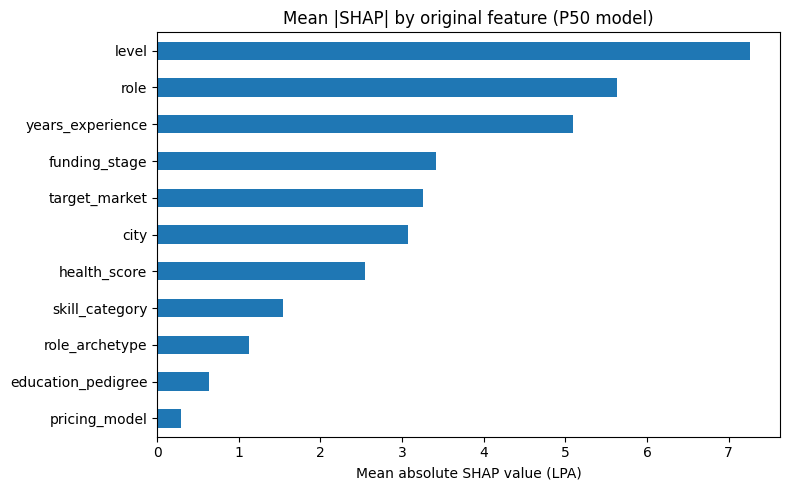

In [13]:
explainer = shap.TreeExplainer(quantile_models[0.50])
sample = X_test_t[:300]
shap_values = explainer.shap_values(sample)

feature_names = preprocessor.get_feature_names_out()


def original_feature_for(name):
    if name.startswith("num__"):
        return name[len("num__"):]
    remainder = name[len("cat__"):]
    for col in sorted(CATEGORICAL_FEATURES, key=len, reverse=True):
        if remainder == col or remainder.startswith(col + "_"):
            return col
    return remainder


agg = {}
for i, name in enumerate(feature_names):
    col = original_feature_for(name)
    agg[col] = agg.get(col, 0.0) + np.abs(shap_values[:, i]).mean()

importance = pd.Series(agg).sort_values(ascending=True)
importance.plot(kind="barh", figsize=(8, 5), title="Mean |SHAP| by original feature (P50 model)")
plt.xlabel("Mean absolute SHAP value (LPA)")
plt.tight_layout()
plt.show()


`years_experience`, `level`, `target_market` (the cross-border premium), and
`health_score` dominate — exactly the story this project set out to tell: the
company's actual computed unit economics matter as much as who the candidate is.

## 11. CTC statutory breakup

`ctc_rules.py` deterministically splits a predicted cash CTC per India's Code on Wages.
Components always sum exactly to the input CTC (the special allowance is the balancing
term).


In [14]:
example = compute_ctc_breakup(ctc_lpa=24.0, city="Bengaluru")
for row in example.as_rows():
    print(f"{row['component']:<32s} Rs.{row['lpa']:.2f} LPA")
print(f"{'TOTAL':<32s} Rs.{sum(r['lpa'] for r in example.as_rows()):.2f} LPA  (target: {example.ctc_lpa})")


Basic + DA                       Rs.12.00 LPA
HRA                              Rs.6.00 LPA
Special Allowance                Rs.0.58 LPA
LTA                              Rs.1.00 LPA
Variable / Performance Bonus     Rs.2.40 LPA
Employer EPF Contribution        Rs.1.44 LPA
Gratuity (accrued)               Rs.0.58 LPA
TOTAL                            Rs.24.00 LPA  (target: 24.0)


## 12. ESOP overlay — a documented assumption, not a scraped figure

Exact cash:equity mixes by funding stage aren't publicly standardized, so this is an
explicit, funding-stage-indexed table (front-loaded to earlier, riskier stages) rather
than a claimed fact.


In [15]:
esop_table = pd.DataFrame(
    {"esop_ratio_of_cash": {stage: cfg["esop_ratio"] for stage, cfg in domain.FUNDING_STAGES.items()}}
)
esop_table


,esop_ratio_of_cash
Bootstrapped,0.00
Seed,0.35
Series A,0.25
Series B,0.18
Series C+,0.12
Pre-IPO / Public,0.06


**Risk-adjusted expected value, not just paper FMV.** The annualized ESOP figure
above is a paper face value. `saas_metrics.esop_expected_value()` is a second,
explicitly-labeled heuristic on top of it: expected value = FMV x probability of a
liquidity event x typical payout multiple on realization, both indexed to health
band. This is *not* Black-Scholes or any formal options-pricing model — an illiquid
private-company option has no observable strike price or volatility, so pricing one
that way would be false precision, not rigor.


In [16]:
for band, assumptions in sm.ESOP_EXIT_ASSUMPTIONS.items():
    ev = sm.esop_expected_value(esop_annualized_fmv_lpa=10.0, health_score={"At-risk": 20, "Cash-constrained": 45, "Healthy": 65, "Hypergrowth / Efficient": 85}[band])
    print(f"{band:<26s} FMV=Rs.10.00 LPA -> liquidity_prob={assumptions['liquidity_probability']:.2f}  "
          f"payout_mult={assumptions['payout_multiple']:.2f}  expected_value=Rs.{ev['expected_value_lpa']:.2f} LPA")


At-risk                    FMV=Rs.10.00 LPA -> liquidity_prob=0.15  payout_mult=0.30  expected_value=Rs.0.45 LPA
Cash-constrained           FMV=Rs.10.00 LPA -> liquidity_prob=0.30  payout_mult=0.50  expected_value=Rs.1.50 LPA
Healthy                    FMV=Rs.10.00 LPA -> liquidity_prob=0.55  payout_mult=0.80  expected_value=Rs.4.40 LPA
Hypergrowth / Efficient    FMV=Rs.10.00 LPA -> liquidity_prob=0.75  payout_mult=1.10  expected_value=Rs.8.25 LPA


## 13. Compa-ratio lookup

The empirical median cash CTC for each role+level+city+funding-stage segment,
precomputed from the training data — this is what `main.py` divides a new prediction
by to report a compa-ratio ("1.08x segment median").


In [17]:
compa_lookup = df.groupby(["role", "level", "city", "funding_stage"])[TARGET].median()
compa_lookup.sample(5, random_state=1).round(2)


role                         level             city            funding_stage   
Marketing Manager            Lead / Principal  Indore          Pre-IPO / Public    59.08
UI/UX Designer               Senior            Hyderabad       Series A            26.61
Sales Development Rep (SDR)  Lead / Principal  Remote (other)  Series C+           36.24
QA Engineer                  Mid               Jaipur          Series A            14.08
Enterprise Sales Manager     Lead / Principal  Jaipur          Series A            53.15
Name: cash_ctc_lpa, dtype: float64

## 14. Export artifacts

Re-runs `train_model.py`'s `main()` to (re-)write every artifact `main.py` loads —
preprocessor, the three quantile models, the linear baseline, the compa-ratio lookup,
the funding-stage default health scores, and the metrics/SHAP summaries used on the
Methodology page.


In [18]:
import train_model
train_model.main()


Linear Regression (baseline): R2=0.884  MAE=3.80 LPA  MAPE=21.3%
HistGradientBoostingRegressor (P50, production): R2=0.961  MAE=1.95 LPA  MAPE=7.6%
P25<=P50<=P75 holds for 81.4% of test predictions


5-fold CV  Linear Regression (baseline): R2=0.878+/-0.004  MAE=3.78+/-0.04 LPA


5-fold CV  HistGradientBoostingRegressor (P50, production): R2=0.959+/-0.003  MAE=1.94+/-0.04 LPA
Face-validity: Chennai, Domestic, Mid, Series A SaaS (cited: Rs.7.9-8.7 LPA for Chennai engineers)
  -> predicted P50=15.7 LPA, cited range=(6.0, 12.0), OUT OF RANGE
Face-validity: Bengaluru, Cross-border, Senior, Series C+ (cited: FAANG/cross-border tier Rs.35-60 LPA)
  -> predicted P50=68.1 LPA, cited range=(28.0, 70.0), OK
Face-validity: Domestic Seed-stage SaaS, Junior (cited IT-services-adjacent range: Rs.3.5-6 LPA)
  -> predicted P50=4.6 LPA, cited range=(4.0, 12.0), OK



Top SHAP feature contributions (P50 model, mean |impact|, LPA):
  num__years_experience: 4.77
  cat__level_Junior: 4.24
  cat__target_market_Cross-border: 2.57
  num__health_score: 2.52
  cat__level_Mid: 1.91
  cat__role_ML / AI Engineer: 1.03
  cat__funding_stage_Pre-IPO / Public: 0.96
  cat__role_archetype_GTM: 0.95
  cat__funding_stage_Series C+: 0.93
  cat__level_Lead / Principal: 0.93



Artifacts written to C:\Users\Zenith Joshua\Downloads\SalaryPredictor-main\SalaryPredictor-main\artifacts


## Limitations

- **Synthetic data.** Calibrated against real 2026 benchmarks, but not real payroll —
  real Indian SaaS payroll data is confidential and wasn't available to this project.
- **SaaS-specific scope.** Calibrated for Indian B2B SaaS roles; not generic IT
  services, non-tech sectors, or executive compensation.
- **ESOP is a modeled assumption**, not a scraped or verified figure.
- **The "SaaS Health Score" is an authored rubric**, not an industry-standard formula —
  no single canonical one exists.
- **The live-signal feed (`market_signals.py`) is a labeled simulation** — see the
  Methodology page for why a real integration wasn't attempted here.
